In [ ]:
# Task 29: Relationship Analysis

## Objective
Create a scatter plot to analyze the relationship between
two numerical variables and describe the observed pattern.

## Deliverables
- Student performance dataset
- Scatter plot
- Correlation analysis
- Description of the relationship
- At least three observations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Student study hours
study_hours = [
    1.0, 1.5, 2.0, 2.5, 3.0,
    3.5, 4.0, 4.5, 5.0, 5.5,
    6.0, 6.5, 7.0, 7.5, 8.0,
    8.5, 9.0, 9.5, 10.0, 10.5
]

# Corresponding examination marks
exam_marks = [
    35, 42, 38, 48, 44,
    54, 50, 61, 56, 66,
    60, 72, 67, 76, 71,
    83, 79, 88, 84, 96
]

# Generate student IDs
student_ids = [
    f"S{i:03d}" for i in range(1, 21)
]

# Create DataFrame
df = pd.DataFrame({
    "student_id": student_ids,
    "study_hours": study_hours,
    "exam_marks": exam_marks
})

print("Student performance dataset created successfully!")
print("Total students:", len(df))

display(df)

Student performance dataset created successfully!
Total students: 20


,student_id,study_hours,exam_marks
0,S001,1.0,35
1,S002,1.5,42
2,S003,2.0,38
3,S004,2.5,48
4,S005,3.0,44
5,S006,3.5,54
6,S007,4.0,50
7,S008,4.5,61
8,S009,5.0,56
9,S010,5.5,66


In [3]:
# Save original dataset
df.to_csv(
    "student_performance.csv",
    index=False
)

# Load CSV using Pandas
df = pd.read_csv("student_performance.csv")

print("Dataset loaded successfully!")

display(df.head(10))

Dataset loaded successfully!


,student_id,study_hours,exam_marks
0,S001,1.0,35
1,S002,1.5,42
2,S003,2.0,38
3,S004,2.5,48
4,S005,3.0,44
5,S006,3.5,54
6,S007,4.0,50
7,S008,4.5,61
8,S009,5.0,56
9,S010,5.5,66


In [4]:
print("DATASET INFORMATION")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

DATASET INFORMATION
Total rows: 20
Total columns: 3

Column names:
['student_id', 'study_hours', 'exam_marks']

Data types:
student_id      object
study_hours    float64
exam_marks       int64
dtype: object

First five records:


,student_id,study_hours,exam_marks
0,S001,1.0,35
1,S002,1.5,42
2,S003,2.0,38
3,S004,2.5,48
4,S005,3.0,44



Last five records:


,student_id,study_hours,exam_marks
15,S016,8.5,83
16,S017,9.0,79
17,S018,9.5,88
18,S019,10.0,84
19,S020,10.5,96


In [5]:
print("STUDENT PERFORMANCE STATISTICAL SUMMARY")

display(
    df[["study_hours", "exam_marks"]].describe()
)

STUDENT PERFORMANCE STATISTICAL SUMMARY


,study_hours,exam_marks
count,20.00000,20.0000
mean,5.75000,63.5000
std,2.95804,17.6113
min,1.00000,35.0000
25%,3.37500,49.5000
50%,5.75000,63.5000
75%,8.12500,76.7500
max,10.50000,96.0000


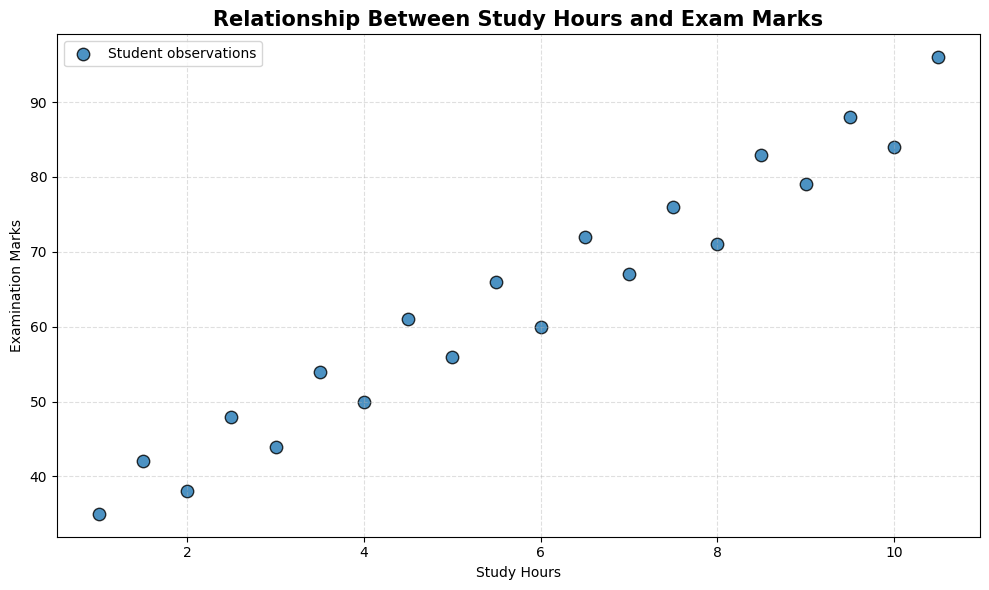

In [6]:
# Create charts folder
Path("charts").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["study_hours"],
    df["exam_marks"],
    marker="o",
    s=80,
    edgecolors="black",
    alpha=0.8,
    label="Student observations"
)

# Add chart title and axis labels
plt.title(
    "Relationship Between Study Hours and Exam Marks",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Study Hours")
plt.ylabel("Examination Marks")

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.legend()
plt.tight_layout()

# Save the chart
plt.savefig(
    "charts/study_hours_vs_exam_marks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
correlation = df["study_hours"].corr(
    df["exam_marks"]
)

print("=" * 55)
print("             CORRELATION ANALYSIS")
print("=" * 55)

print(
    f"\nPearson correlation coefficient: {correlation:.4f}"
)

if correlation > 0:
    print("Relationship direction: Positive")
elif correlation < 0:
    print("Relationship direction: Negative")
else:
    print("Relationship direction: No linear correlation")

if abs(correlation) >= 0.7:
    strength = "Strong"
elif abs(correlation) >= 0.4:
    strength = "Moderate"
elif abs(correlation) >= 0.2:
    strength = "Weak"
else:
    strength = "Very weak"

print("Relationship strength:", strength)

             CORRELATION ANALYSIS

Pearson correlation coefficient: 0.9754
Relationship direction: Positive
Relationship strength: Strong


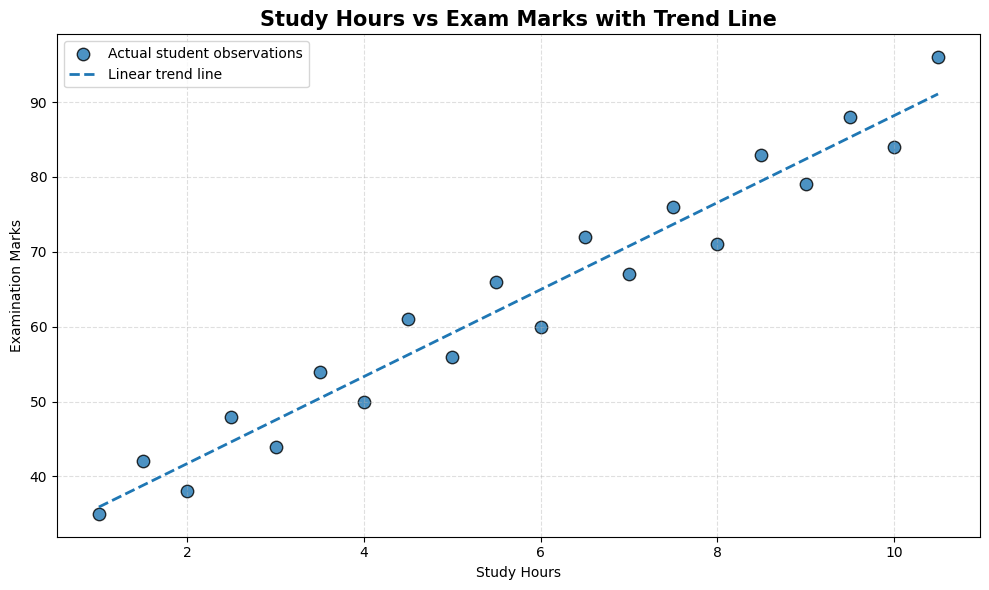

Slope: 5.81
Intercept: 30.11


In [8]:
# Calculate the best-fit linear trend line
slope, intercept = np.polyfit(
    df["study_hours"],
    df["exam_marks"],
    1
)

predicted_marks = (
    slope * df["study_hours"] + intercept
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["study_hours"],
    df["exam_marks"],
    s=80,
    edgecolors="black",
    alpha=0.8,
    label="Actual student observations"
)

plt.plot(
    df["study_hours"],
    predicted_marks,
    linestyle="--",
    linewidth=2,
    label="Linear trend line"
)

plt.title(
    "Study Hours vs Exam Marks with Trend Line",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Study Hours")
plt.ylabel("Examination Marks")

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.legend()
plt.tight_layout()
plt.show()

print(f"Slope: {slope:.2f}")
print(f"Intercept: {intercept:.2f}")

In [9]:
# Calculate statistics
average_hours = df["study_hours"].mean()
average_marks = df["exam_marks"].mean()

minimum_hours = df["study_hours"].min()
maximum_hours = df["study_hours"].max()

minimum_marks = df["exam_marks"].min()
maximum_marks = df["exam_marks"].max()

print("=" * 60)
print("             RELATIONSHIP ANALYSIS OBSERVATIONS")
print("=" * 60)

print(
    f"\n1. The average study time is "
    f"{average_hours:.2f} hours."
)

print(
    f"\n2. The average examination mark is "
    f"{average_marks:.2f}."
)

print(
    f"\n3. Study hours range from "
    f"{minimum_hours} to {maximum_hours} hours."
)

print(
    f"\n4. Examination marks range from "
    f"{minimum_marks} to {maximum_marks}."
)

print(
    f"\n5. The correlation coefficient is "
    f"{correlation:.4f}."
)

print(
    "\n6. Relationship: Strong positive linear association."
)

print(
    "\nConclusion: Students with higher study hours "
    "generally obtained higher marks in this sample."
)

             RELATIONSHIP ANALYSIS OBSERVATIONS

1. The average study time is 5.75 hours.

2. The average examination mark is 63.50.

3. Study hours range from 1.0 to 10.5 hours.

4. Examination marks range from 35 to 96.

5. The correlation coefficient is 0.9754.

6. Relationship: Strong positive linear association.

Conclusion: Students with higher study hours generally obtained higher marks in this sample.


In [10]:
relationship_summary = pd.DataFrame({
    "Metric": [
        "Total Students",
        "Average Study Hours",
        "Average Exam Marks",
        "Minimum Study Hours",
        "Maximum Study Hours",
        "Minimum Exam Marks",
        "Maximum Exam Marks",
        "Pearson Correlation",
        "Relationship Direction",
        "Relationship Strength"
    ],

    "Value": [
        len(df),
        round(average_hours, 2),
        round(average_marks, 2),
        minimum_hours,
        maximum_hours,
        minimum_marks,
        maximum_marks,
        round(correlation, 4),
        "Positive",
        strength
    ]
})

display(relationship_summary)

,Metric,Value
0,Total Students,20
1,Average Study Hours,5.75
2,Average Exam Marks,63.5
3,Minimum Study Hours,1.0
4,Maximum Study Hours,10.5
5,Minimum Exam Marks,35
6,Maximum Exam Marks,96
7,Pearson Correlation,0.9754
8,Relationship Direction,Positive
9,Relationship Strength,Strong


In [11]:
print("CORRELATION MATRIX")

correlation_matrix = df[
    ["study_hours", "exam_marks"]
].corr()

display(correlation_matrix)

CORRELATION MATRIX


,study_hours,exam_marks
study_hours,1.000000,0.975446
exam_marks,0.975446,1.000000


In [12]:
# Save original dataset
df.to_csv(
    "student_performance.csv",
    index=False
)

# Save relationship summary
relationship_summary.to_csv(
    "relationship_summary.csv",
    index=False
)

# Save correlation matrix
correlation_matrix.to_csv(
    "correlation_matrix.csv"
)

print("All project files exported successfully!")

All project files exported successfully!


In [13]:
from google.colab import files

files.download("student_performance.csv")
files.download("relationship_summary.csv")
files.download("correlation_matrix.csv")

files.download(
    "charts/study_hours_vs_exam_marks.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>